<a href="https://colab.research.google.com/github/FelipeCostadeSouza/calc_numtrue/blob/main/Atividade_3_CN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
def bissecao(f, a, b, tol=1e-6, max_iter=100):
    # Verificação do teorema do valor intermédio
    if f(a) * f(b) > 0:
        return None, 0, [], "Falha: f(a) e f(b) têm o mesmo sinal (f(a)*f(b) > 0)."

    aproximacoes = []
    x_anterior = a

    for i in range(1, max_iter + 1):
        x = (a + b) / 2.0
        aproximacoes.append(x)

        # Critérios de parada: erro entre iterações e resíduo |f(x)|
        if abs(x - x_anterior) < tol or abs(f(x)) < tol:
            return x, i, aproximacoes, "Convergência atingida."

        if f(a) * f(x) < 0:
            b = x
        else:
            a = x

        x_anterior = x

    return aproximacoes[-1], max_iter, aproximacoes, "Falha: Número máximo de iterações atingido sem convergência."


def newton(f, df, x0, tol=1e-6, max_iter=100):
    aproximacoes = [x0]
    x_atual = x0

    for i in range(1, max_iter + 1):
        derivada = df(x_atual)

        # Verificação se a derivada é zero ou muito próxima de zero
        if abs(derivada) < 1e-12:
            return x_atual, i - 1, aproximacoes, "Falha: Derivada nula ou muito próxima de zero."

        x_novo = x_atual - f(x_atual) / derivada
        aproximacoes.append(x_novo)

        # Critérios de parada
        if abs(x_novo - x_atual) < tol or abs(f(x_novo)) < tol:
            return x_novo, i, aproximacoes, "Convergência atingida."

        x_atual = x_novo

    return aproximacoes[-1], max_iter, aproximacoes, "Falha: Número máximo de iterações atingido sem convergência."


def secante(f, x0, x1, tol=1e-6, max_iter=100):
    aproximacoes = [x0, x1]
    x_ant = x0
    x_atual = x1

    for i in range(1, max_iter + 1):
        denominador = f(x_atual) - f(x_ant)

        # Verificação se o denominador é zero ou muito próximo de zero
        if abs(denominador) < 1e-12:
            return x_atual, i - 1, aproximacoes, "Falha: Denominador nulo ou muito próximo de zero."

        x_novo = x_atual - f(x_atual) * (x_atual - x_ant) / denominador
        aproximacoes.append(x_novo)

        # Critérios de parada
        if abs(x_novo - x_atual) < tol or abs(f(x_novo)) < tol:
            return x_novo, i, aproximacoes, "Convergência atingida."

        x_ant = x_atual
        x_atual = x_novo

    return aproximacoes[-1], max_iter, aproximacoes, "Falha: Número máximo de iterações atingido sem convergência."

In [ ]:
import math
import pandas as pd

# f1(x) = x^2 - 2
f1 = lambda x: x**2 - 2
df1 = lambda x: 2*x

# f2(x) = x^3 - x - 2
f2 = lambda x: x**3 - x - 2
df2 = lambda x: 3*x**2 - 1

# f3(x) = e^(-x) - x
f3 = lambda x: math.exp(-x) - x
df3 = lambda x: -math.exp(-x) - 1

# f4(x) = x^3 - 2x + 2
f4 = lambda x: x**3 - 2*x + 2
df4 = lambda x: 3*x**2 - 2

testes = [
    {
        "nome": "f1(x) = x^2 - 2",
        "f": f1, "df": df1,
        "bissecao": (1.0, 2.0),
        "newton": 1.5,
        "secante": (1.0, 2.0)
    },
    {
        "nome": "f2(x) = x^3 - x - 2",
        "f": f2, "df": df2,
        "bissecao": (1.0, 2.0),
        "newton": 1.5,
        "secante": (1.0, 2.0)
    },
    {
        "nome": "f3(x) = e^(-x) - x",
        "f": f3, "df": df3,
        "bissecao": (0.0, 1.0),
        "newton": 0.5,
        "secante": (0.0, 1.0)
    },
    {
        "nome": "f4(x) = x^3 - 2x + 2",
        "f": f4, "df": df4,
        "bissecao": (-2.0, -1.0),
        "newton": -2.0,
        "secante": (-2.0, -1.0)
    }
]

tabela_resultados = []

for t in testes:
    func_nome = t["nome"]
    f = t["f"]
    df = t["df"]

    # --- Método da Bisseção ---
    a, b = t["bissecao"]
    raiz, iters, _, status = bissecao(f, a, b)
    residuos = abs(f(raiz)) if raiz is not None else "N/A"
    tabela_resultados.append({
        "Função": func_nome,
        "Método": "Bisseção",
        "Valores iniciais": f"[{a}, {b}]",
        "Raiz aproximada": f"{raiz:.6f}" if isinstance(raiz, float) else "N/A",
        "|f(x)| final": f"{residuos:.2e}" if isinstance(residuos, float) else "N/A",
        "Iterações/resultado": f"{iters} iter. ({status})"
    })

    # --- Método de Newton ---
    x0 = t["newton"]
    raiz, iters, _, status = newton(f, df, x0)
    residuos = abs(f(raiz)) if raiz is not None else "N/A"
    tabela_resultados.append({
        "Função": func_nome,
        "Método": "Newton",
        "Valores iniciais": f"x0 = {x0}",
        "Raiz aproximada": f"{raiz:.6f}" if isinstance(raiz, float) else "N/A",
        "|f(x)| final": f"{residuos:.2e}" if isinstance(residuos, float) else "N/A",
        "Iterações/resultado": f"{iters} iter. ({status})"
    })

    # --- Método da Secante ---
    x0, x1 = t["secante"]
    raiz, iters, _, status = secante(f, x0, x1)
    residuos = abs(f(raiz)) if raiz is not None else "N/A"
    tabela_resultados.append({
        "Função": func_nome,
        "Método": "Secante",
        "Valores iniciais": f"({x0}, {x1})",
        "Raiz aproximada": f"{raiz:.6f}" if isinstance(raiz, float) else "N/A",
        "|f(x)| final": f"{residuos:.2e}" if isinstance(residuos, float) else "N/A",
        "Iterações/resultado": f"{iters} iter. ({status})"
    })

df_resultados = pd.DataFrame(tabela_resultados)
df_resultados

,Função,Método,Valores iniciais,Raiz aproximada,|f(x)| final,Iterações/resultado
0,f1(x) = x^2 - 2,Bisseção,"[1.0, 2.0]",1.414214,1.62e-06,20 iter. (Convergência atingida.)
1,f1(x) = x^2 - 2,Newton,x0 = 1.5,1.414214,4.51e-12,3 iter. (Convergência atingida.)
2,f1(x) = x^2 - 2,Secante,"(1.0, 2.0)",1.414214,8.93e-10,5 iter. (Convergência atingida.)
3,f2(x) = x^3 - x - 2,Bisseção,"[1.0, 2.0]",1.521380,4.27e-06,20 iter. (Convergência atingida.)
4,f2(x) = x^3 - x - 2,Newton,x0 = 1.5,1.521380,5.89e-07,2 iter. (Convergência atingida.)
5,f2(x) = x^3 - x - 2,Secante,"(1.0, 2.0)",1.521380,7.02e-09,6 iter. (Convergência atingida.)
6,f3(x) = e^(-x) - x,Bisseção,"[0.0, 1.0]",0.567143,2.35e-07,20 iter. (Convergência atingida.)
7,f3(x) = e^(-x) - x,Newton,x0 = 0.5,0.567143,1.96e-07,2 iter. (Convergência atingida.)
8,f3(x) = e^(-x) - x,Secante,"(0.0, 1.0)",0.567143,2.54e-08,4 iter. (Convergência atingida.)
9,f4(x) = x^3 - 2x + 2,Bisseção,"[-2.0, -1.0]",-1.769292,3.52e-06,20 iter. (Convergência atingida.)


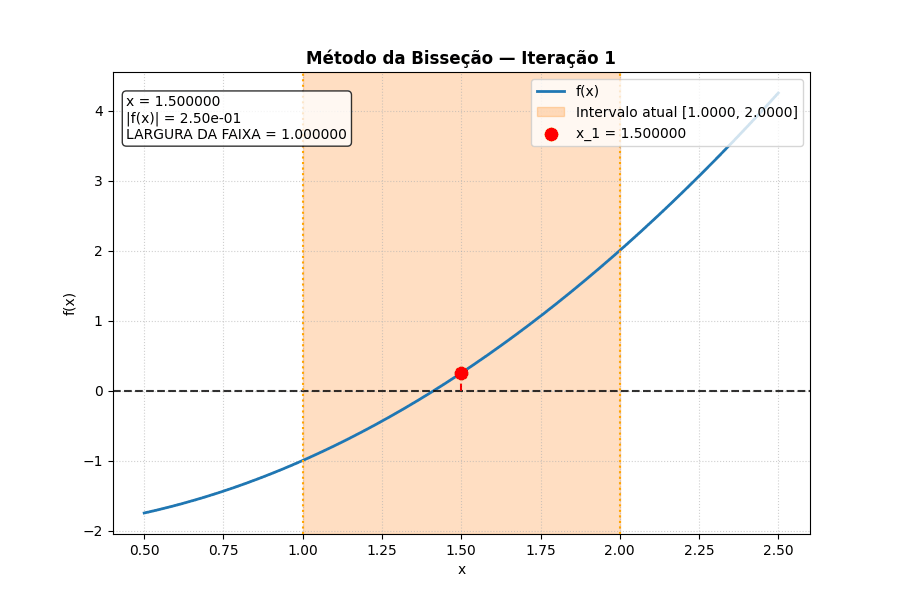

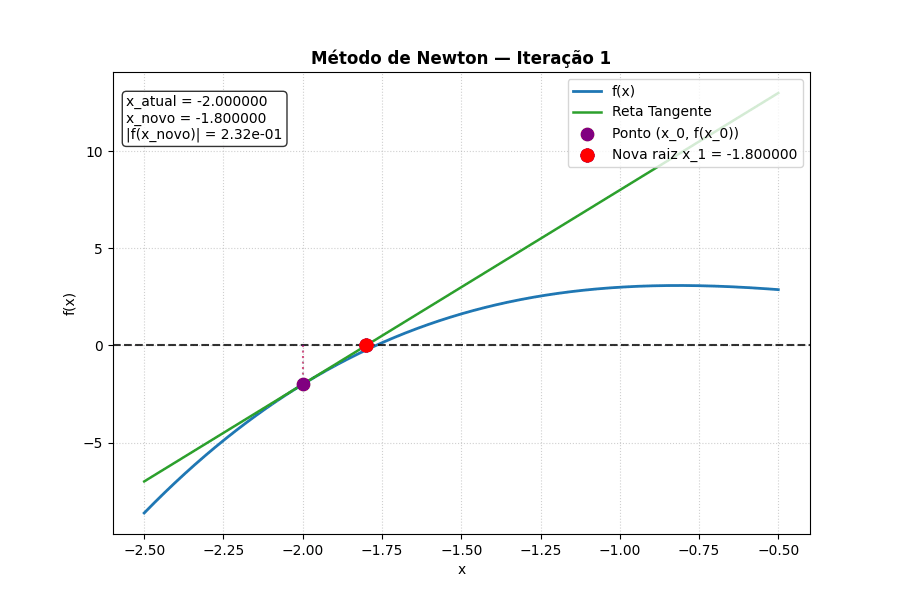

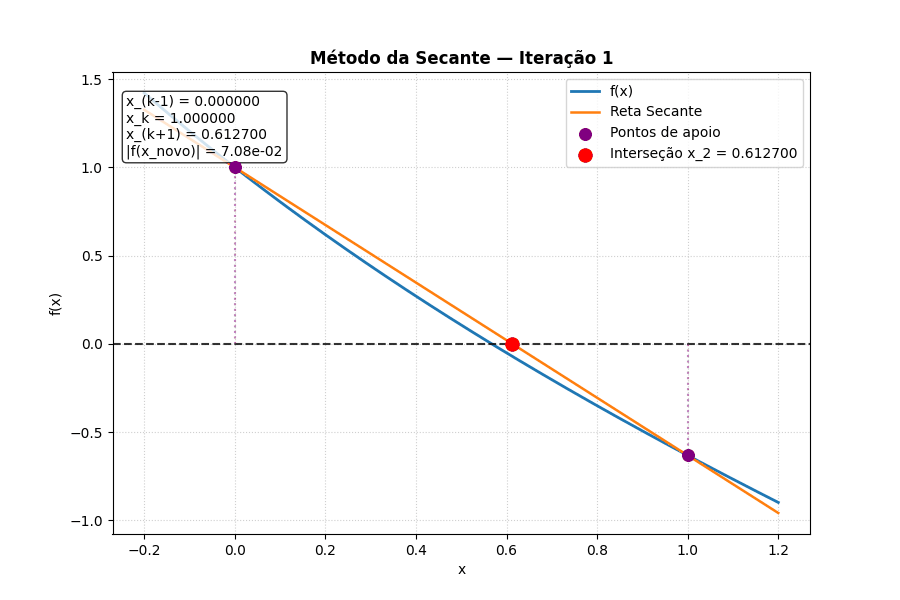

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import Image, display

def bissecao_anim(f, a, b, tol=1e-6, max_iter=100):
    passos = []
    a_curr, b_curr = a, b

    if f(a) * f(b) > 0:
        return None, passos

    x_ant = a_curr
    for i in range(1, max_iter + 1):
        x = (a_curr + b_curr) / 2.0
        passos.append({
            'iter': i,
            'a': a_curr, 'b': b_curr, 'x': x,
            'fx': f(x), 'resíduo': abs(f(x))
        })

        if abs(x - x_ant) < tol or abs(f(x)) < tol:
            break

        if f(a_curr) * f(x) < 0:
            b_curr = x
        else:
            a_curr = x
        x_ant = x

    return x, passos


def newton_anim(f, df, x0, tol=1e-6, max_iter=100):
    passos = []
    x_curr = x0

    for i in range(1, max_iter + 1):
        derivada = df(x_curr)
        if abs(derivada) < 1e-12:
            break

        x_novo = x_curr - f(x_curr) / derivada
        passos.append({
            'iter': i,
            'x_k': x_curr,
            'x_next': x_novo,
            'fx_k': f(x_curr),
            'dfx_k': derivada,
            'resíduo': abs(f(x_novo))
        })

        if abs(x_novo - x_curr) < tol or abs(f(x_novo)) < tol:
            break
        x_curr = x_novo

    return x_curr, passos


def secante_anim(f, x0, x1, tol=1e-6, max_iter=100):
    passos = []
    x_ant, x_curr = x0, x1

    for i in range(1, max_iter + 1):
        den = f(x_curr) - f(x_ant)
        if abs(den) < 1e-12:
            break

        x_novo = x_curr - f(x_curr) * (x_curr - x_ant) / den
        passos.append({
            'iter': i,
            'x_ant': x_ant,
            'x_curr': x_curr,
            'x_novo': x_novo,
            'fx_ant': f(x_ant),
            'fx_curr': f(x_curr),
            'resíduo': abs(f(x_novo))
        })

        if abs(x_novo - x_curr) < tol or abs(f(x_novo)) < tol:
            break

        x_ant = x_curr
        x_curr = x_novo

    return x_novo, passos


def criar_gif_bissecao(f, a_init, b_init, nome_arquivo="bissecao.gif"):
    _, passos = bissecao_anim(f, a_init, b_init)
    fig, ax = plt.subplots(figsize=(9, 6), dpi=100)

    x_vals = np.linspace(a_init - 0.5, b_init + 0.5, 500)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        p = passos[frame]

        ax.plot(x_vals, y_vals, label="f(x)", color="#1f77b4", linewidth=2)
        ax.axhline(0, color="black", linestyle="--", alpha=0.8)

        for prev in passos[:frame]:
            ax.axvspan(prev['a'], prev['b'], color='gray', alpha=0.08)
            ax.scatter([prev['x']], [prev['fx']], color='gray', alpha=0.4, s=30)

        ax.axvspan(p['a'], p['b'], color='#ff7f0e', alpha=0.25, label=f"Intervalo atual [{p['a']:.4f}, {p['b']:.4f}]")
        ax.axvline(p['a'], color='orange', linestyle=':', linewidth=1.5)
        ax.axvline(p['b'], color='orange', linestyle=':', linewidth=1.5)

        ax.scatter([p['x']], [p['fx']], color='red', s=80, zorder=5, label=f"x_{p['iter']} = {p['x']:.6f}")
        ax.vlines(p['x'], 0, p['fx'], color='red', linestyle='--', alpha=0.7)

        ax.set_title(f"Método da Bisseção — Iteração {p['iter']}", fontsize=12, fontweight='bold')
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.grid(True, linestyle=':', alpha=0.6)

        info_text = f"x = {p['x']:.6f}\n|f(x)| = {p['resíduo']:.2e}\nLARGURA DA FAIXA = {abs(p['b'] - p['a']):.6f}"
        ax.text(0.02, 0.95, info_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        ax.legend(loc="upper right")

    anim = animation.FuncAnimation(fig, update, frames=len(passos), interval=1500)
    anim.save(nome_arquivo, writer='pillow', fps=0.7)
    plt.close()
    display(Image(filename=nome_arquivo))


def criar_gif_newton(f, df, x0, x_domain, nome_arquivo="newton.gif"):
    _, passos = newton_anim(f, df, x0)
    fig, ax = plt.subplots(figsize=(9, 6), dpi=100)

    x_vals = np.linspace(x_domain[0], x_domain[1], 500)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        p = passos[frame]

        ax.plot(x_vals, y_vals, label="f(x)", color="#1f77b4", linewidth=2)
        ax.axhline(0, color="black", linestyle="--", alpha=0.8)

        for prev in passos[:frame]:
            ax.scatter([prev['x_k']], [prev['fx_k']], color='gray', alpha=0.3, s=30)
            ax.scatter([prev['x_next']], [0], color='gray', alpha=0.3, s=30)

        tangente = lambda x: p['fx_k'] + p['dfx_k'] * (x - p['x_k'])
        ax.plot(x_vals, [tangente(x) for x in x_vals], color='#2ca02c', linestyle='-', linewidth=1.8, label="Reta Tangente")

        ax.scatter([p['x_k']], [p['fx_k']], color='purple', s=80, zorder=5, label=f"Ponto (x_{p['iter']-1}, f(x_{p['iter']-1}))")
        ax.vlines(p['x_k'], 0, p['fx_k'], color='purple', linestyle=':', alpha=0.7)

        ax.scatter([p['x_next']], [0], color='red', s=90, zorder=6, label=f"Nova raiz x_{p['iter']} = {p['x_next']:.6f}")

        ax.set_title(f"Método de Newton — Iteração {p['iter']}", fontsize=12, fontweight='bold')
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.grid(True, linestyle=':', alpha=0.6)

        info_text = f"x_atual = {p['x_k']:.6f}\nx_novo = {p['x_next']:.6f}\n|f(x_novo)| = {p['resíduo']:.2e}"
        ax.text(0.02, 0.95, info_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        ax.legend(loc="upper right")

    anim = animation.FuncAnimation(fig, update, frames=len(passos), interval=1500)
    anim.save(nome_arquivo, writer='pillow', fps=0.7)
    plt.close()
    display(Image(filename=nome_arquivo))


def criar_gif_secante(f, x0, x1, x_domain, nome_arquivo="secante.gif"):
    _, passos = secante_anim(f, x0, x1)
    fig, ax = plt.subplots(figsize=(9, 6), dpi=100)

    x_vals = np.linspace(x_domain[0], x_domain[1], 500)
    y_vals = [f(x) for x in x_vals]

    def update(frame):
        ax.clear()
        p = passos[frame]

        ax.plot(x_vals, y_vals, label="f(x)", color="#1f77b4", linewidth=2)
        ax.axhline(0, color="black", linestyle="--", alpha=0.8)

        for prev in passos[:frame]:
            ax.scatter([prev['x_ant'], prev['x_curr']], [prev['fx_ant'], prev['fx_curr']], color='gray', alpha=0.3, s=20)

        m = (p['fx_curr'] - p['fx_ant']) / (p['x_curr'] - p['x_ant'])
        secante_line = lambda x: p['fx_curr'] + m * (x - p['x_curr'])

        ax.plot(x_vals, [secante_line(x) for x in x_vals], color='#ff7f0e', linestyle='-', linewidth=1.8, label="Reta Secante")

        ax.scatter([p['x_ant'], p['x_curr']], [p['fx_ant'], p['fx_curr']], color='purple', s=70, zorder=5, label="Pontos de apoio")
        ax.vlines(p['x_ant'], 0, p['fx_ant'], color='purple', linestyle=':', alpha=0.5)
        ax.vlines(p['x_curr'], 0, p['fx_curr'], color='purple', linestyle=':', alpha=0.5)

        ax.scatter([p['x_novo']], [0], color='red', s=90, zorder=6, label=f"Interseção x_{p['iter']+1} = {p['x_novo']:.6f}")

        ax.set_title(f"Método da Secante — Iteração {p['iter']}", fontsize=12, fontweight='bold')
        ax.set_xlabel("x")
        ax.set_ylabel("f(x)")
        ax.grid(True, linestyle=':', alpha=0.6)

        info_text = f"x_(k-1) = {p['x_ant']:.6f}\nx_k = {p['x_curr']:.6f}\nx_(k+1) = {p['x_novo']:.6f}\n|f(x_novo)| = {p['resíduo']:.2e}"
        ax.text(0.02, 0.95, info_text, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

        ax.legend(loc="upper right")

    anim = animation.FuncAnimation(fig, update, frames=len(passos), interval=1500)
    anim.save(nome_arquivo, writer='pillow', fps=0.7)
    plt.close()
    display(Image(filename=nome_arquivo))


criar_gif_bissecao(f1, 1.0, 2.0, "bissecao_f1.gif")
criar_gif_newton(f4, df4, -2.0, (-2.5, -0.5), "newton_f4.gif")
criar_gif_secante(f3, 0.0, 1.0, (-0.2, 1.2), "secante_f3.gif")